In [24]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
iris=load_iris(as_frame=True)
df =  iris.frame
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [25]:
print(df.isna().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


In [26]:
print(df.duplicated().sum())

1


In [27]:
df.drop_duplicates(inplace=True)
print(df.isna().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


In [28]:
from sklearn.model_selection import train_test_split
x=df.drop(["target"],axis=1)
y=df["target"]
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2)

In [29]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score
knn = KNeighborsClassifier(3)
knn.fit(x_train,y_train)
y_pred=knn.predict(x_train)
print(confusion_matrix(y_pred,y_train))

[[40  0  0]
 [ 0 39  2]
 [ 0  3 35]]


In [30]:
print("accuracy",accuracy_score(y_train,y_pred))
print("precision",precision_score(y_train,y_pred,average='macro'))
print("recall",recall_score(y_train,y_pred,average='macro'))
print("f1",f1_score(y_train,y_pred,average='macro'))

accuracy 0.957983193277311
precision 0.9574240479246897
recall 0.9581724581724581
f1 0.9576974564926374


In [34]:
y_pred2=knn.predict(x_test)
print(confusion_matrix(y_test,y_pred2))

[[10  0  0]
 [ 0  8  0]
 [ 0  1 11]]


In [35]:
print("accuracy",accuracy_score(y_test,y_pred2))
print("precision",precision_score(y_test,y_pred2,average='macro'))
print("recall",recall_score(y_test,y_pred2,average='macro'))
print("f1",f1_score(y_test,y_pred2,average='macro'))

accuracy 0.9666666666666667
precision 0.9629629629629629
recall 0.9722222222222222
f1 0.9658994032395567


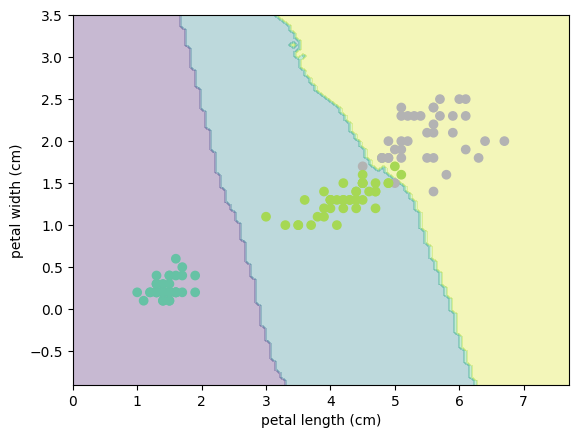

In [55]:
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
knn2 =  KNeighborsClassifier(9)
x_data=x_train[['petal length (cm)','petal width (cm)']]
knn2.fit(x_data,y_train)
DecisionBoundaryDisplay.from_estimator(knn2,x_data,response_method='predict',alpha=0.3)
plt.scatter(x_data['petal length (cm)'],x_data['petal width (cm)'],c=y_train,cmap="Set2")
plt.show()

In [58]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(x_train,y_train)
y_pred_lr=lr.predict(x_test)
print("consfuion matrix\n",confusion_matrix(y_pred_lr,y_test))

consfuion matrix
 [[10  0  0]
 [ 0  8  1]
 [ 0  0 11]]


In [59]:
print("accuracy",accuracy_score(y_test,y_pred_lr))
print("precision",precision_score(y_test,y_pred_lr,average='macro'))
print("recall",recall_score(y_test,y_pred_lr,average='macro'))
print("f1",f1_score(y_test,y_pred_lr,average='macro'))

accuracy 0.9666666666666667
precision 0.9629629629629629
recall 0.9722222222222222
f1 0.9658994032395567


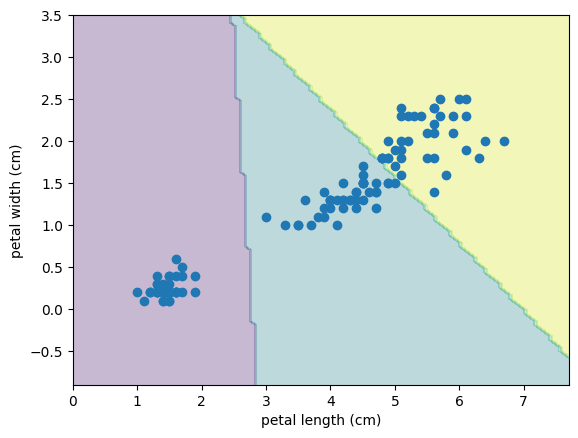

In [63]:
data=x_train[['petal length (cm)','petal width (cm)']]
lr2=LogisticRegression()
lr2.fit(data,y_train)
DecisionBoundaryDisplay.from_estimator(lr2,data,response_method='predict',alpha=0.3)
plt.scatter(data['petal length (cm)'],data['petal width (cm)'])

In [69]:
print("entyer flower measuemnts")
sl=float(input("sepal lenght (4-8)"))
sw=float(input("sepal width (2 to 4.5)"))
pl=float(input("petal lenght (1-7)"))
pw=float(input("petal widht (0.2-0.5)"))
user_data = pd.DataFrame(
    [[sl,sw,pl,pw]],
    columns=['sepal length (cm)','sepal width (cm)','petal length (cm)','petal width (cm)']
)
result = lr.predict(user_data)[0]

print('result',result)

entyer flower measuemnts
sepal lenght (4-8)6
sepal width (2 to 4.5)4
petal lenght (1-7)6
petal widht (0.2-0.5)0.2
result 1
